In [3]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from collections import Counter
from pathlib import Path
import csv


pd.set_option('display.max_colwidth', 90)
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.unicode_minus'] = False


In [4]:
BASE_DIR = Path.cwd().parent
DATA_DIR = BASE_DIR / "Data" / "raw"

ddi = pd.read_csv(DATA_DIR / "db_drug_interactions.csv")
eg = pd.read_csv(DATA_DIR / "eg_drugs.csv")

In [5]:
ddi.info()

<class 'pandas.DataFrame'>
RangeIndex: 191541 entries, 0 to 191540
Data columns (total 3 columns):
 #   Column                   Non-Null Count   Dtype
---  ------                   --------------   -----
 0   Drug 1                   191541 non-null  str  
 1   Drug 2                   191541 non-null  str  
 2   Interaction Description  191541 non-null  str  
dtypes: str(3)
memory usage: 24.9 MB


In [6]:
ddi.duplicated().sum()

np.int64(0)

In [7]:
ddi.isnull().sum()

Drug 1                     0
Drug 2                     0
Interaction Description    0
dtype: int64

In [8]:
ddi.columns = ['Drug 1', 'Drug 2', 'Interaction Description']
ddi['Drug 1'] = ddi['Drug 1'].str.strip().str.title()
ddi['Drug 2'] = ddi['Drug 2'].str.strip().str.title()

In [9]:
def extract_effect(desc):
    desc_l = desc.lower()
    if 'increase' in desc_l and 'serum concentration' in desc_l:
        return 'increase_concentration'
    if 'decrease' in desc_l and 'serum concentration' in desc_l:
        return 'decrease_concentration'
    if 'increase' in desc_l and 'risk' in desc_l:
        return 'increase_risk'
    if 'decrease' in desc_l:
        return 'decrease_effect'
    if 'metabolism' in desc_l:
        return 'metabolism_change'
    return 'other'

ddi['effect_type'] = ddi['Interaction Description'].apply(extract_effect)

In [10]:
def extract_mechanism(desc):
    d = desc.lower()
    if 'cardiotoxic' in d: return 'cardiotoxic'
    if 'qtc' in d: return 'qtc_prolongation'
    if 'bradycardic' in d: return 'bradycardic'
    if 'hypokalemic' in d: return 'hypokalemic'
    if 'hypoglycemic' in d: return 'hypoglycemic'
    if 'neuroexcitatory' in d: return 'neuroexcitatory'
    if 'anticoagulant' in d: return 'anticoagulant'
    if 'photosensitizing' in d: return 'photosensitizing'
    if 'nephrotoxic' in d: return 'nephrotoxic'
    if 'hepatotoxic' in d: return 'hepatotoxic'
    return 'other'

ddi['mechanism'] = ddi['Interaction Description'].apply(extract_mechanism)

In [11]:
def extract_severity(desc):
    d = desc.lower()
    if 'risk or severity of adverse effects can be increased' in d:
        return 'high'
    if 'may increase' in d or 'may decrease' in d:
        return 'medium'
    if 'can be increased' in d or 'can be decreased' in d:
        return 'medium'
    return 'low'

ddi['severity'] = ddi['Interaction Description'].apply(extract_severity)

In [12]:
print(ddi.shape)
print(ddi['Drug 1'].nunique(), ddi['Drug 2'].nunique())
print(ddi['effect_type'].value_counts())
print(ddi['mechanism'].value_counts())
print(ddi['severity'].value_counts())

(191541, 6)
1634 1606
effect_type
increase_risk             61397
decrease_effect           51040
other                     39421
increase_concentration    24375
decrease_concentration    10308
metabolism_change          5000
Name: count, dtype: int64
mechanism
other               174058
qtc_prolongation      6582
anticoagulant         3393
hypoglycemic          2109
bradycardic           1277
cardiotoxic           1245
hypokalemic           1204
neuroexcitatory        936
nephrotoxic            662
hepatotoxic             64
photosensitizing        11
Name: count, dtype: int64
severity
medium    129506
high       60722
low         1313
Name: count, dtype: int64


In [13]:
from collections import Counter
all_drugs = pd.concat([ddi['Drug 1'], ddi['Drug 2']])
top_drugs = Counter(all_drugs).most_common(20)

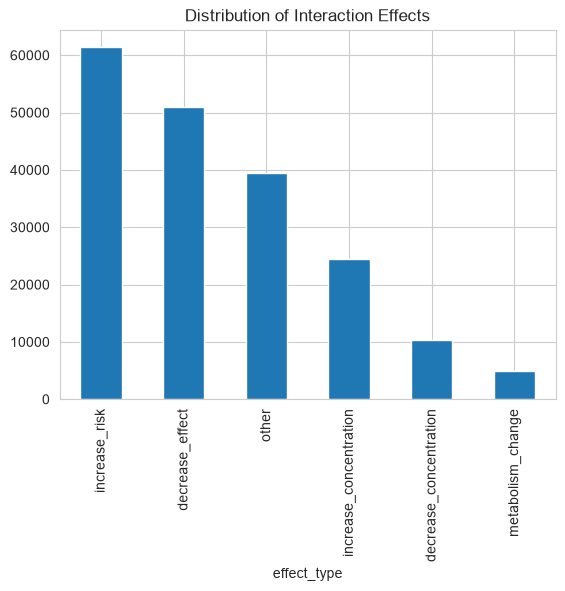

In [14]:
import matplotlib.pyplot as plt
ddi['effect_type'].value_counts().plot(kind='bar')
plt.title('Distribution of Interaction Effects')
plt.show()

In [15]:
import networkx as nx

G = nx.from_pandas_edgelist(ddi, 'Drug 1', 'Drug 2')
print(f"Nodes: {G.number_of_nodes()}")
print(f"Edges: {G.number_of_edges()}")
print(f"Density: {nx.density(G):.4f}")

Nodes: 1701
Edges: 191135
Density: 0.1322


In [16]:
pairs_set = set(zip(ddi['Drug 1'], ddi['Drug 2']))
asymmetric = [(a,b) for (a,b) in pairs_set if (b,a) not in pairs_set]
print(f"count of asymmetric pairs: {len(asymmetric)}")

count of asymmetric pairs: 191018


In [17]:
eg.info()

<class 'pandas.DataFrame'>
RangeIndex: 26562 entries, 0 to 26561
Data columns (total 25 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   id                           26562 non-null  int64  
 1   name                         26562 non-null  str    
 2   arabic                       26562 non-null  str    
 3   active                       23805 non-null  str    
 4   company                      26252 non-null  str    
 5   price                        26557 non-null  str    
 6   oldprice                     11362 non-null  str    
 7   availability                 26219 non-null  float64
 8   barcode                      10532 non-null  str    
 9   slug                         26561 non-null  str    
 10  units                        26562 non-null  int64  
 11  description                  25427 non-null  str    
 12  uses                         8107 non-null   str    
 13  matched_fda_ingredients    

uses                           69.5
barcode                        60.3
oldprice                       57.2
matched_fda_ingredients        26.3
active                         10.4
description                     4.3
availability                    1.3
company                         1.2
price                           0.0
slug                            0.0
arabic                          0.0
id                              0.0
name                            0.0
units                           0.0
uses_summary                    0.0
uses_summary_en                 0.0
warning_high_blood_pressure     0.0
warning_diabetes                0.0
warning_pregnancy               0.0
warning_lactation               0.0
warning_kidney                  0.0
warning_liver                   0.0
warning_heart                   0.0
warnings_summary                0.0
warnings_summary_en             0.0
dtype: float64


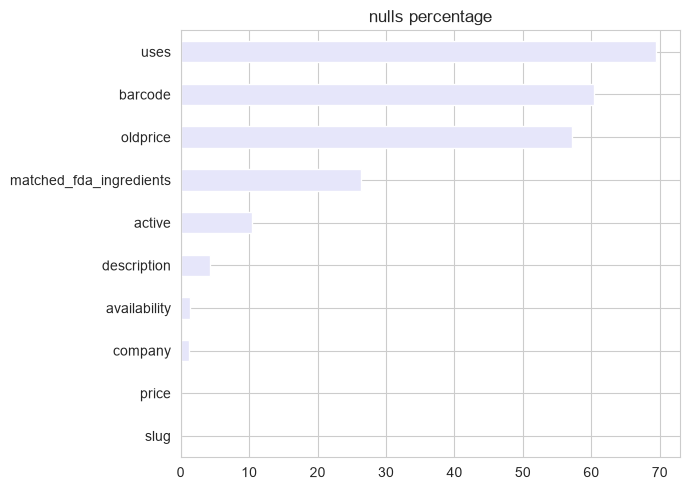

In [18]:
missing_pct = (eg.isnull().mean() * 100).sort_values(ascending=False)
print(missing_pct.round(1))

plt.figure(figsize=(7, 5))
missing_pct[missing_pct > 0].sort_values().plot(kind='barh', color='lavender')
plt.title('nulls percentage')
plt.tight_layout()
plt.show()

In [19]:
def parse_price(x):
    if pd.isna(x):
        return np.nan
    m = re.search(r'\d+(\.\d+)?', str(x).replace(',', ''))
    return float(m.group()) if m else np.nan

eg['price_clean'] = eg['price'].apply(parse_price)

print(eg.price_clean.describe().round(1))

count       26557.0
mean         1910.6
std        208729.3
min             0.0
25%            32.0
50%            79.0
75%           180.0
max      34000000.0
Name: price_clean, dtype: float64


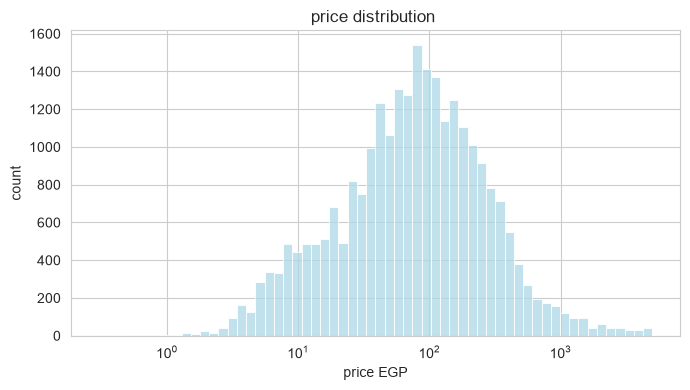

In [20]:
valid_price = eg.price_clean[(eg.price_clean > 0) & (eg.price_clean <= 5000)]

plt.figure(figsize=(7, 4))
sns.histplot(valid_price, bins=60, log_scale=(True, False), color='lightblue')
plt.title('price distribution ')
plt.xlabel('price EGP')
plt.ylabel('count')
plt.tight_layout()
plt.show()

In [21]:
print(eg.availability.describe().round(1))

count    26219.0
mean         4.0
std         61.7
min         -3.0
25%          0.0
50%          0.0
75%          1.0
max       3837.0
Name: availability, dtype: float64


In [22]:
print(f'most common availability values:\n{eg.availability.value_counts().head(8)}')

most common availability values:
availability
0.0    19049
1.0     2763
2.0     1143
3.0      638
4.0      384
5.0      274
6.0      184
7.0      170
Name: count, dtype: int64


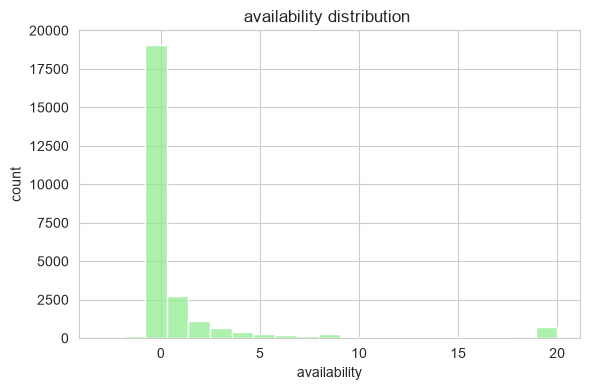

In [23]:
plt.figure(figsize=(6, 4))
sns.histplot(eg.availability.clip(upper=20), bins=21, color='lightgreen')
plt.title('availability distribution ')
plt.xlabel('availability')
plt.ylabel('count')
plt.tight_layout()
plt.show()

one ingredient: 13,859 (58.2%)
combo products : 9,946 (41.8%)


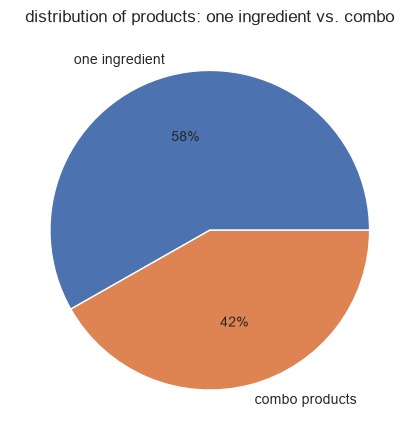

In [24]:
active = eg.active.dropna()
is_combo = active.str.contains(r'\+')

print(f"one ingredient: {(~is_combo).sum():,} ({(~is_combo).mean():.1%})")
print(f"combo products : {is_combo.sum():,} ({is_combo.mean():.1%})")

plt.figure(figsize=(4.5, 4.5))
pd.Series({'one ingredient': (~is_combo).sum(), 'combo products': is_combo.sum()}).plot(
    kind='pie', autopct='%1.0f%%', colors=['#4C72B0', '#DD8452'], ylabel='')
plt.title('distribution of products: one ingredient vs. combo')
plt.tight_layout()
plt.show()

warning_pregnancy              26.6
warning_kidney                 23.4
warning_heart                  19.9
warning_lactation              16.5
warning_liver                  15.3
warning_high_blood_pressure    12.1
warning_diabetes               11.8
dtype: float64


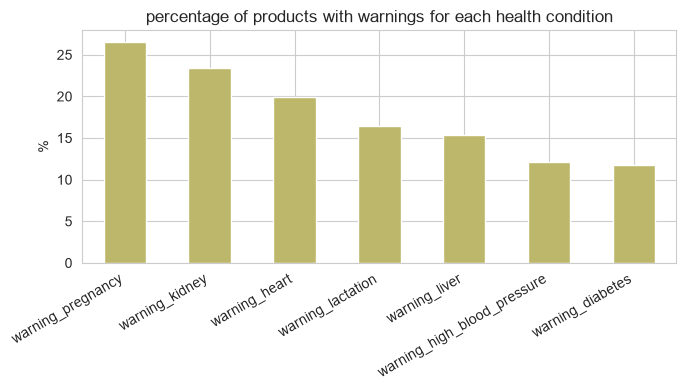

In [25]:
warning_cols = [c for c in eg.columns if c.startswith('warning_')]
warning_rates = (eg[warning_cols].mean() * 100).sort_values(ascending=False)
print(warning_rates.round(1))

plt.figure(figsize=(7, 4))
warning_rates.plot(kind='bar', color='darkkhaki')
plt.title('percentage of products with warnings for each health condition')
plt.ylabel('%')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

In [26]:
active_norm = (
	eg["active"]
	.dropna()
	.astype(str)
	.str.lower()
	.str.replace(r"\s*\+\s*", "+", regex=True)
)

market_drug_tokens = set()
for value in active_norm:
	for ingredient in re.split(r"\s*\+\s*|\s*\|\s*", value):
		ingredient = re.sub(r"\s+", " ", ingredient).strip()
		if ingredient:
			market_drug_tokens.add(ingredient)

ddi_drugs = pd.Index(ddi["Drug 1"].str.lower()).union(ddi["Drug 2"].str.lower())
found_on_market = market_drug_tokens.intersection(ddi_drugs)
coverage_drugs = len(found_on_market) / len(ddi_drugs)

ddi_lower_1 = ddi['Drug 1'].str.lower()
ddi_lower_2 = ddi['Drug 2'].str.lower()
both_on_market = ddi[ddi_lower_1.isin(found_on_market) & ddi_lower_2.isin(found_on_market)]

coverage_pairs = len(both_on_market) / len(ddi)
print(f"count of interaction pairs where both drugs are on the Egyptian market: {len(both_on_market):,} out of {len(ddi):,} ({coverage_pairs:.1%})")

count of interaction pairs where both drugs are on the Egyptian market: 64,606 out of 191,541 (33.7%)


In [27]:
print("DDI")
print(f"unique drugs: {ddi[['Drug 1', 'Drug 2']].nunique().sum():,}")

print("Egyptian Drugs")
print(f"all rows: {len(eg):,}")
print(f"products with one active ingredient / combo: {(~is_combo).sum():,} / {is_combo.sum():,}")
print(f"percentage of null values in active: {eg.active.isnull().mean():.1%}")

print("Data Integration")

active_norm = (
    eg["active"]
    .dropna()
    .astype(str)
    .str.lower()
    .str.replace(r"\s*\+\s*", "+", regex=True)
)

market_drug_tokens = set()
for value in active_norm:
    for ingredient in re.split(r"\s*\+\s*|\s*\|\s*", value):
        ingredient = re.sub(r"\s+", " ", ingredient).strip()
        if ingredient:
            market_drug_tokens.add(ingredient)

ddi_drugs = pd.Index(ddi["Drug 1"].str.lower()).union(ddi["Drug 2"].str.lower())
found_on_market = market_drug_tokens.intersection(ddi_drugs)
coverage_drugs = len(found_on_market) / len(ddi_drugs)

print(f"drug coverage: {coverage_drugs:.1%} ({len(found_on_market):,} out of {len(ddi_drugs):,})")
print(f"interaction pair coverage: {coverage_pairs:.1%} ({len(both_on_market):,} out of {len(ddi):,})")

DDI
unique drugs: 3,240
Egyptian Drugs
all rows: 26,562
products with one active ingredient / combo: 13,859 / 9,946
percentage of null values in active: 10.4%
Data Integration
drug coverage: 0.3% (896 out of 266,703)
interaction pair coverage: 33.7% (64,606 out of 191,541)
